# Projet 31 — Tableau de bord marocain du commerce extérieur

**Binôme :** LAILA ACHAOUR\ DOUAE EL BATEOUI\ IMANE RAJAA
**Projet :** n° 31 — Tableau de bord marocain du commerce extérieur (niveau débutant, visualisation + analyse)  
**Date :** 10\11\2026

**Source retenue :** UN Comtrade (API publique *preview*), reporter Maroc (504). Source de contrôle croisé suggérée : Bank Al-Maghrib (bkam.ma) / Office des changes.

**Règles :** aucune donnée n'est inventée. Tous les chiffres affichés par ce notebook proviennent de l'exécution des cellules sur les données téléchargées. Les requêtes sont journalisées dans `data/journal_requetes.csv`.

In [ ]:
# Bibliothèques principales
import os, time, platform, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests, sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings('ignore', category=FutureWarning)
GRAINE_ALEATOIRE = 42
for d in ('data', 'figures', 'tables'):
    os.makedirs(d, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Versions :', 'numpy', np.__version__, '| pandas', pd.__version__,
      '| sklearn', sklearn.__version__, '| matplotlib', matplotlib.__version__)

Versions : numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1 | matplotlib 3.10.0


## 1. Problématique et hypothèses

**Décision commerciale :** un exportateur ou une institution de promotion du commerce doit savoir où se situent les principaux déséquilibres du commerce extérieur marocain, par produit (chapitre HS à 2 chiffres) et par partenaire.

- **Unité d'analyse :** chapitre HS2 × flux (X exportations, M importations) × année ; et partenaire × flux × année pour les totaux.
- **Période :** 2019–2024 (les années réellement disponibles sont détectées automatiquement).
- **Variable cible :** aucune (projet descriptif). Indicateurs : exportations, importations, solde (X − M), taux de couverture (X/M), parts par produit et par partenaire.
- **Hypothèses de travail :** H1 le déficit commercial est structurel ; H2 il est concentré sur un petit nombre de chapitres ; H3 les échanges sont concentrés sur quelques partenaires européens. Elles sont testées descriptivement, sans prétention causale.

**Écart assumé par rapport à la fiche :** la fiche indique HS2 01–24. Nous récupérons **tous** les chapitres HS2 afin de pouvoir vérifier la cohérence avec le total (contrôle « cohérence des totaux ») et de ne pas exclure les produits industriels et miniers majeurs.

## 2. Accès aux données

- Documentation officielle : <https://uncomtrade.org/docs/un-comtrade-api/>
- Endpoint *preview* (sans clé, **500 lignes maximum par requête**, quotas de fréquence) : `https://comtradeapi.un.org/public/v1/preview/C/A/HS`
- Stratégie : une requête par année × flux pour les chapitres HS2 du monde (`cmdCode=AG2`, partenaire 0), et une requête par année × flux × partenaire pour le total (`cmdCode=TOTAL`). Chaque requête reste sous 500 lignes.
- Partenaires retenus : France 251, Espagne 724, Allemagne 276, Italie 380, Royaume-Uni 826, États-Unis 842 (code Comtrade), Chine 156.
- **Piège :** ne jamais additionner « monde » et partenaires (double comptage).

In [ ]:
REPORTER = 504                     # Maroc
ANNEES = list(range(2019, 2025))   # 2019-2024
FLUX = ['X', 'M']
PARTENAIRES = {0: 'Monde', 251: 'France', 724: 'Espagne', 276: 'Allemagne',
               380: 'Italie', 826: 'Royaume-Uni', 842: 'États-Unis', 156: 'Chine'}
BASE_URL = 'https://comtradeapi.un.org/public/v1/preview/C/A/HS'
FORCER_TELECHARGEMENT = False      # True pour ignorer le cache data/
PAUSE_S = 1.2                      # pause entre requêtes (quota)
print('URL exemple :', f"{BASE_URL}?reporterCode={REPORTER}&period=2023&partnerCode=0&cmdCode=AG2&flowCode=X")

URL exemple : https://comtradeapi.un.org/public/v1/preview/C/A/HS?reporterCode=504&period=2023&partnerCode=0&cmdCode=AG2&flowCode=X


## 3. Chargement

Les erreurs HTTP (429 quota, 5xx) sont réessayées puis journalisées ; une réponse vide est signalée. Les données brutes sont mises en cache dans `data/` pour que le « Run all » soit reproductible et ne re-sollicite pas l'API.

In [ ]:
journal = []

def appel(annee, flux, partenaire, cmd, essais=3):
    params = {'reporterCode': REPORTER, 'period': annee, 'partnerCode': partenaire,
              'cmdCode': cmd, 'flowCode': flux, 'maxRecords': 500,
              'format': 'JSON', 'includeDesc': 'true'}
    for k in range(essais):
        try:
            r = requests.get(BASE_URL, params=params, timeout=60)
        except requests.RequestException as e:
            journal.append({'url': f'{annee}/{flux}/{partenaire}/{cmd}', 'statut': 'erreur ' + type(e).__name__,
                            'lignes': None, 'horodatage': pd.Timestamp.now().isoformat()})
            time.sleep(3)
            continue
        if r.status_code == 200:
            try:
                data = r.json().get('data') or []
            except ValueError:
                data = []
            journal.append({'url': r.url, 'statut': 200, 'lignes': len(data),
                            'horodatage': pd.Timestamp.now().isoformat()})
            if len(data) >= 500:
                print('ATTENTION : plafond de 500 lignes atteint pour', r.url)
            return data
        journal.append({'url': r.url, 'statut': r.status_code, 'lignes': None,
                        'horodatage': pd.Timestamp.now().isoformat()})
        time.sleep(10 * (k + 1) if r.status_code == 429 else 2)
    return None

def collecter(taches):
    morceaux = []
    for (annee, flux, part, cmd) in taches:
        d = appel(annee, flux, part, cmd)
        if d:
            tmp = pd.DataFrame(d)
            tmp['requete_cmd'] = cmd
            morceaux.append(tmp)
        time.sleep(PAUSE_S)
    return pd.concat(morceaux, ignore_index=True) if morceaux else pd.DataFrame()

FICHIER_BRUT = 'data/comtrade_brut.csv'
if os.path.exists(FICHIER_BRUT) and not FORCER_TELECHARGEMENT:
    brut = pd.read_csv(FICHIER_BRUT, dtype={'cmdCode': str})
    print('Chargé depuis le cache local :', FICHIER_BRUT)
else:
    taches = ([(a, f, 0, 'AG2') for a in ANNEES for f in FLUX] +
              [(a, f, p, 'TOTAL') for a in ANNEES for f in FLUX for p in PARTENAIRES])
    print(len(taches), 'requêtes à envoyer (≈', round(len(taches) * (PAUSE_S + 1) / 60, 1), 'min)')
    brut = collecter(taches)
    if brut.empty:
        raise RuntimeError("Aucune donnée reçue. Vérifier la connexion, le quota ou l'endpoint "
                           "(voir data/journal_requetes.csv). Plan B : un seul flux, 3 à 5 années.")
    brut.to_csv(FICHIER_BRUT, index=False)
if journal:
    jr = pd.DataFrame(journal)
    jr.to_csv('data/journal_requetes.csv', index=False)
    print(jr['statut'].value_counts().to_string())
print('Dimensions brutes :', brut.shape)
print(list(brut.columns))
display(brut.head())

Chargé depuis le cache local : data/comtrade_brut.csv
Dimensions brutes : (1248, 48)
['typeCode', 'freqCode', 'refPeriodId', 'refYear', 'refMonth', 'period', 'reporterCode', 'reporterISO', 'reporterDesc', 'flowCode', 'flowDesc', 'partnerCode', 'partnerISO', 'partnerDesc', 'partner2Code', 'partner2ISO', 'partner2Desc', 'classificationCode', 'classificationSearchCode', 'isOriginalClassification', 'cmdCode', 'cmdDesc', 'aggrLevel', 'isLeaf', 'customsCode', 'customsDesc', 'mosCode', 'motCode', 'motDesc', 'qtyUnitCode', 'qtyUnitAbbr', 'qty', 'isQtyEstimated', 'altQtyUnitCode', 'altQtyUnitAbbr', 'altQty', 'isAltQtyEstimated', 'netWgt', 'isNetWgtEstimated', 'grossWgt', 'isGrossWgtEstimated', 'cifvalue', 'fobvalue', 'primaryValue', 'legacyEstimationFlag', 'isReported', 'isAggregate', 'requete_cmd']


,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate,requete_cmd
0,C,A,20190101,2019,52,2019,504,MAR,Morocco,X,...,False,0.0,False,0.0,3.799538e+07,3.799538e+07,0,False,True,AG2
1,C,A,20190101,2019,52,2019,504,MAR,Morocco,X,...,True,0.0,False,0.0,1.394863e+09,1.394863e+09,4,False,True,AG2
2,C,A,20190101,2019,52,2019,504,MAR,Morocco,X,...,True,0.0,False,0.0,1.213819e+09,1.213819e+09,4,False,True,AG2
3,C,A,20190101,2019,52,2019,504,MAR,Morocco,X,...,False,0.0,False,0.0,1.708618e+05,1.708618e+05,0,False,True,AG2
4,C,A,20190101,2019,52,2019,504,MAR,Morocco,X,...,False,0.0,False,0.0,1.633644e+07,1.633644e+07,0,False,True,AG2


## 4. Dictionnaire de variables

In [ ]:
dictionnaire = pd.DataFrame([
    ['refYear', 'entier (année)', 'année', "Année de référence de l'échange", 'UN Comtrade'],
    ['flowCode', 'texte', 'X / M', 'Flux : X exportation, M importation', 'UN Comtrade'],
    ['partnerCode / partnerDesc', 'entier / texte', 'code M49', 'Partenaire (0 = Monde)', 'UN Comtrade'],
    ['cmdCode / cmdDesc', 'texte', 'HS2', 'Chapitre du Système harmonisé (2 chiffres) ou TOTAL', 'UN Comtrade'],
    ['primaryValue', 'décimal', 'USD courants', 'Valeur commerciale', 'UN Comtrade'],
    ['valeur_musd', 'décimal', 'millions USD', 'primaryValue / 1e6 (variable dérivée)', 'calculée'],
    ['solde', 'décimal', 'millions USD', 'X − M', 'calculée'],
    ['couverture_pct', 'décimal', '%', '100 × X / M', 'calculée'],
], columns=['variable', 'type', 'unité', 'description', 'source'])
display(dictionnaire)

,variable,type,unité,description,source
0,refYear,entier (année),année,Année de référence de l'échange,UN Comtrade
1,flowCode,texte,X / M,"Flux : X exportation, M importation",UN Comtrade
2,partnerCode / partnerDesc,entier / texte,code M49,Partenaire (0 = Monde),UN Comtrade
3,cmdCode / cmdDesc,texte,HS2,Chapitre du Système harmonisé (2 chiffres) ou ...,UN Comtrade
4,primaryValue,décimal,USD courants,Valeur commerciale,UN Comtrade
5,valeur_musd,décimal,millions USD,primaryValue / 1e6 (variable dérivée),calculée
6,solde,décimal,millions USD,X − M,calculée
7,couverture_pct,décimal,%,100 × X / M,calculée


## 5. Qualité et nettoyage

Chaque transformation est tracée dans `journal_nettoyage`. Les années où l'un des deux flux est absent du total mondial sont **exclues** de l'analyse (jamais complétées).

In [ ]:
journal_nettoyage = []
colonnes = [c for c in ['refYear', 'flowCode', 'partnerCode', 'partnerDesc', 'cmdCode', 'cmdDesc',
                        'primaryValue', 'netWgt', 'requete_cmd'] if c in brut.columns]
df = brut[colonnes].copy()
df['cmdCode'] = df['cmdCode'].astype(str).str.strip()
est_chap = df['cmdCode'].str.fullmatch(r'\d{1,2}')
df.loc[est_chap, 'cmdCode'] = df.loc[est_chap, 'cmdCode'].str.zfill(2)
df['refYear'] = df['refYear'].astype(int)
df['partnerCode'] = df['partnerCode'].astype(int)
df['valeur_musd'] = pd.to_numeric(df['primaryValue'], errors='coerce') / 1e6
journal_nettoyage.append('Codes HS normalisés sur 2 caractères ; valeur convertie en millions USD.')

cle = ['refYear', 'flowCode', 'partnerCode', 'cmdCode', 'requete_cmd']
nb_dup = int(df.duplicated(cle).sum())
df = df.drop_duplicates(cle)
journal_nettoyage.append(f'{nb_dup} doublon(s) supprimé(s) sur la clé {cle}.')

manq = df[['valeur_musd']].isna().sum().iloc[0]
neg = int((df['valeur_musd'] <= 0).sum())
journal_nettoyage.append(f'Valeurs manquantes : {manq} ; valeurs nulles ou négatives : {neg} (conservées, signalées).')
df = df.dropna(subset=['valeur_musd'])

tot_monde = (df[(df.requete_cmd == 'TOTAL') & (df.partnerCode == 0)]
             .pivot(index='refYear', columns='flowCode', values='valeur_musd'))
for c in FLUX:
    if c not in tot_monde.columns:
        tot_monde[c] = np.nan
annees_ok = tot_monde.dropna(subset=FLUX).index
exclues = sorted(set(ANNEES) - set(annees_ok))
journal_nettoyage.append(f'Années complètes (X et M disponibles) : {list(annees_ok)} ; exclues : {exclues}.')
if len(annees_ok) == 0:
    raise RuntimeError('Aucune année complète : voir le journal des requêtes.')
ANNEE_REF = int(max(annees_ok))
journal_nettoyage.append(f"Année de référence pour les classements : {ANNEE_REF} (dernière année complète).")

tot = tot_monde.loc[annees_ok, FLUX].copy()
tot['solde'] = tot['X'] - tot['M']
tot['couverture_pct'] = 100 * tot['X'] / tot['M']
tot['var_X_pct'] = tot['X'].pct_change() * 100
tot['var_M_pct'] = tot['M'].pct_change() * 100

hs2 = df[(df.requete_cmd == 'AG2') & (df.partnerCode == 0) & df.cmdCode.str.fullmatch(r'\d{2}')
         & df.refYear.isin(annees_ok)].copy()

# Contrôle de cohérence : somme des chapitres vs total
somme = hs2.groupby(['refYear', 'flowCode'])['valeur_musd'].sum().unstack()
coh = pd.DataFrame({'année': somme.index.astype(int)})
for c in FLUX:
    coh[f'{c} : somme chapitres / total (%)'] = (100 * somme[c] / tot[c]).reindex(somme.index).values
coh = coh.reset_index(drop=True)

print('\n'.join('- ' + j for j in journal_nettoyage))
display(tot.round(1))
display(coh.round(2))

- Codes HS normalisés sur 2 caractères ; valeur convertie en millions USD.
- 0 doublon(s) supprimé(s) sur la clé ['refYear', 'flowCode', 'partnerCode', 'cmdCode', 'requete_cmd'].
- Valeurs manquantes : 0 ; valeurs nulles ou négatives : 0 (conservées, signalées).
- Années complètes (X et M disponibles) : [2019, 2020, 2021, 2022, 2023, 2024] ; exclues : [].
- Année de référence pour les classements : 2024 (dernière année complète).


flowCode,X,M,solde,couverture_pct,var_X_pct,var_M_pct
refYear,,,,,,
2019,29582.4,51048.9,-21466.5,57.9,NaN,NaN
2020,27702.7,44526.4,-16823.7,62.2,-6.4,-12.8
2021,36585.2,58677.6,-22092.4,62.3,32.1,31.8
2022,42183.5,72577.7,-30394.2,58.1,15.3,23.7
2023,42462.8,70645.0,-28182.2,60.1,0.7,-2.7
2024,80568.9,97953.4,-17384.5,82.3,89.7,38.7


,année,X : somme chapitres / total (%),M : somme chapitres / total (%)
0,2019,100.0,100.0
1,2020,100.0,100.0
2,2021,100.0,100.0
3,2022,100.0,100.0
4,2023,100.0,100.0
5,2024,100.0,100.0


## 6. Analyse exploratoire

Six figures numérotées (cinq exigées + une carte de chaleur produit × partenaire). Chaque figure est suivie d'une lecture générée à partir des données ; l'interprétation économique rédigée figure dans le rapport.

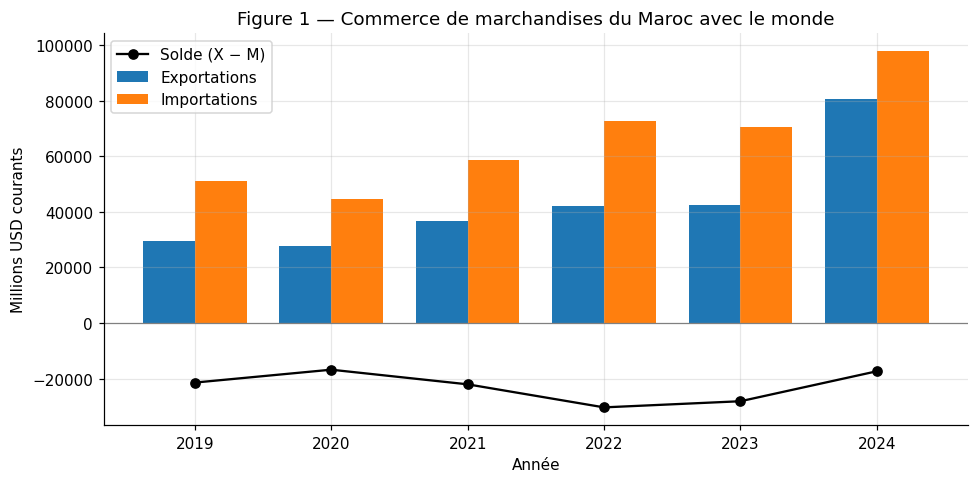

Lecture : en 2024, X = 80 569 M USD, M = 97 953 M USD, solde = -17 385 M USD.


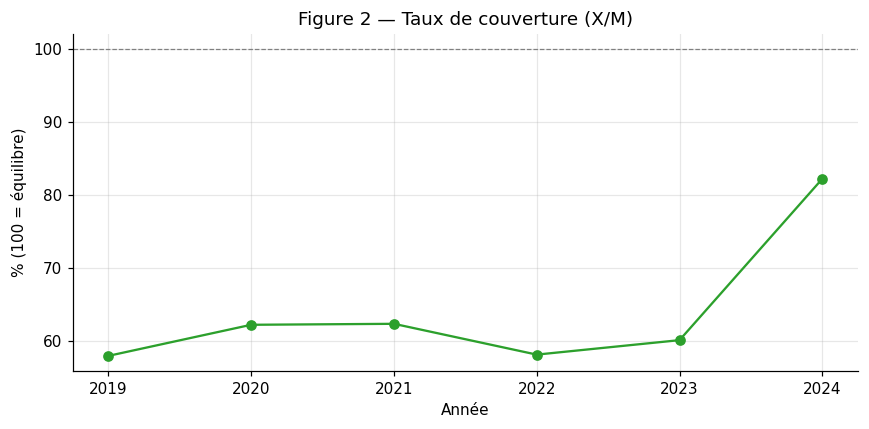

Lecture : taux de couverture 2024 = 82.3 %.


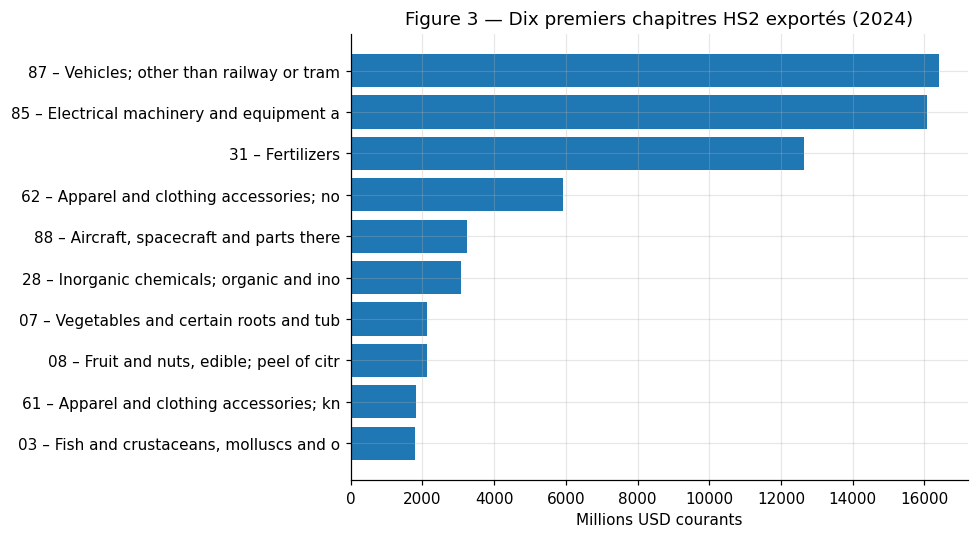

Lecture : premier chapitre exporté = 87 – Vehicles; other than railway or tram (20.3 % des exportations) ; les 10 premiers pèsent 80.9 %.


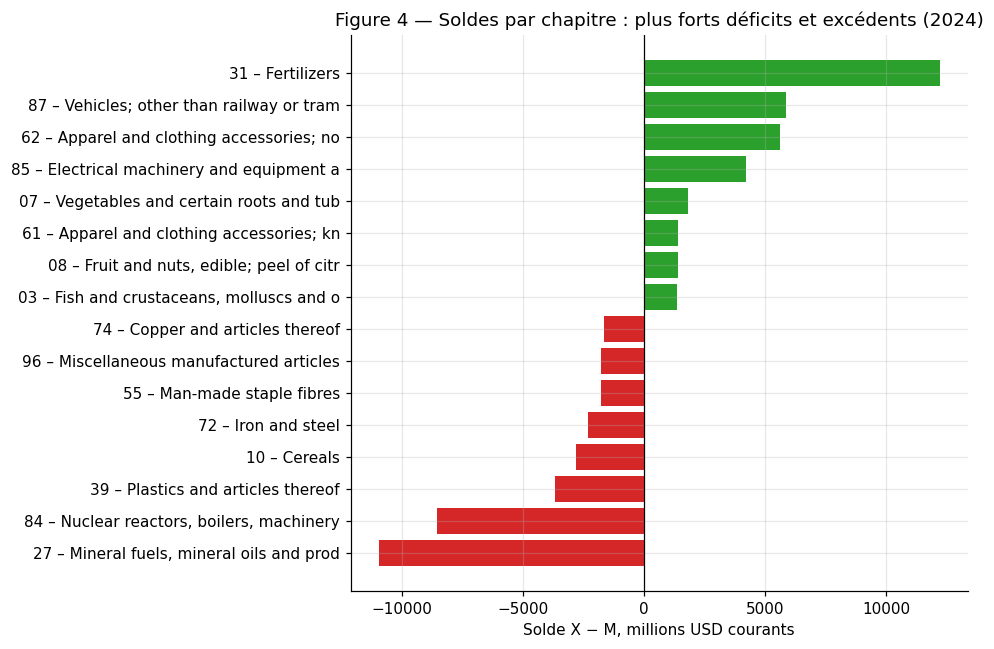

Lecture : plus fort déficit = 27 – Mineral fuels, mineral oils and prod (-10 973 M USD) ; les 5 plus gros déficits cumulent -28 334 M USD.


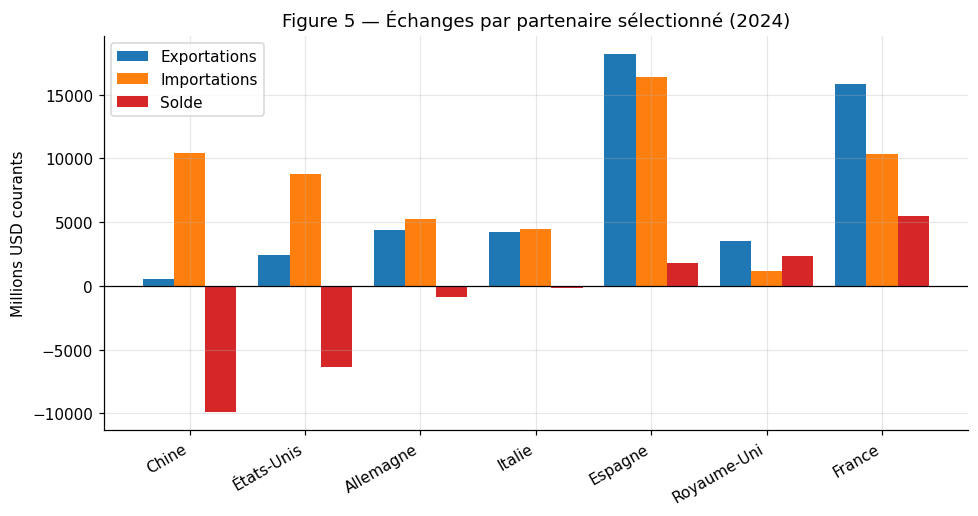

Lecture : premier client parmi les partenaires retenus = Espagne (22.6 % des X totales) ; plus fort déficit bilatéral = Chine (-9 908 M USD).


In [ ]:
TEX = False   # True lors de l'export LaTeX

def fmt(v, d=0):
    s = f"{v:,.{d}f}"
    return s.replace(',', '§').replace('.', ',').replace('§', '\\,' if TEX else '\u202f')

def sauver(nom):
    plt.tight_layout()
    plt.savefig(f'figures/{nom}.png', dpi=200, bbox_inches='tight')
    plt.show()

# Table produits de l'année de référence
w = (hs2[hs2.refYear == ANNEE_REF].pivot_table(index='cmdCode', columns='flowCode',
                                                values='valeur_musd', aggfunc='sum').fillna(0))
for c in FLUX:
    if c not in w.columns:
        w[c] = 0.0
if 'cmdDesc' in hs2.columns:
    desc = hs2.drop_duplicates('cmdCode').set_index('cmdCode')['cmdDesc'].astype(str)
    w['libelle'] = desc.reindex(w.index).fillna('')
else:
    w['libelle'] = ''
w['solde'] = w['X'] - w['M']
w['part_X_pct'] = 100 * w['X'] / w['X'].sum()
w['part_M_pct'] = 100 * w['M'] / w['M'].sum()

def lib(code):
    return f"{code} – {w.loc[code, 'libelle'][:36]}"

# Figure 1 : X, M, solde
fig, ax = plt.subplots(figsize=(9, 4.5))
idx = tot.index.values.astype(float); bw = 0.38
ax.bar(idx - bw/2, tot['X'], bw, label='Exportations', color='tab:blue')
ax.bar(idx + bw/2, tot['M'], bw, label='Importations', color='tab:orange')
ax.plot(idx, tot['solde'], 'k-o', label='Solde (X − M)')
ax.axhline(0, color='grey', lw=.8)
ax.set_title('Figure 1 — Commerce de marchandises du Maroc avec le monde')
ax.set_xlabel('Année'); ax.set_ylabel('Millions USD courants'); ax.legend()
sauver('fig1_x_m_solde')
r = tot.loc[ANNEE_REF]
print(f"Lecture : en {ANNEE_REF}, X = {fmt(r.X)} M USD, M = {fmt(r.M)} M USD, solde = {fmt(r.solde)} M USD.")

# Figure 2 : taux de couverture
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tot.index, tot['couverture_pct'], '-o', color='tab:green')
ax.axhline(100, color='grey', ls='--', lw=.8)
ax.set_title('Figure 2 — Taux de couverture (X/M)')
ax.set_xlabel('Année'); ax.set_ylabel('% (100 = équilibre)')
sauver('fig2_couverture')
print(f"Lecture : taux de couverture {ANNEE_REF} = {r.couverture_pct:.1f} %.")

# Figure 3 : top 10 chapitres exportés
top = w.sort_values('X', ascending=False).head(10)[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([lib(c) for c in top.index], top['X'], color='tab:blue')
ax.set_title(f'Figure 3 — Dix premiers chapitres HS2 exportés ({ANNEE_REF})')
ax.set_xlabel('Millions USD courants')
sauver('fig3_top_export')
t1 = w['X'].idxmax()
print(f"Lecture : premier chapitre exporté = {lib(t1)} ({w.loc[t1,'part_X_pct']:.1f} % des exportations) ; "
      f"les 10 premiers pèsent {w.sort_values('X', ascending=False).head(10)['part_X_pct'].sum():.1f} %.")

# Figure 4 : plus forts déficits / excédents
s = w['solde'].sort_values()
sel = pd.concat([s.head(8), s.tail(8)])
sel = sel[~sel.index.duplicated()]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([lib(c) for c in sel.index], sel.values,
        color=['tab:red' if v < 0 else 'tab:green' for v in sel.values])
ax.axvline(0, color='k', lw=.8)
ax.set_title(f'Figure 4 — Soldes par chapitre : plus forts déficits et excédents ({ANNEE_REF})')
ax.set_xlabel('Solde X − M, millions USD courants')
sauver('fig4_soldes_produits')
d1 = s.index[0]
print(f"Lecture : plus fort déficit = {lib(d1)} ({fmt(s.iloc[0])} M USD) ; "
      f"les 5 plus gros déficits cumulent {fmt(s.head(5).sum())} M USD.")

# Figure 5 : partenaires
pa = (df[(df.requete_cmd == 'TOTAL') & (df.partnerCode != 0) & (df.refYear == ANNEE_REF)]
      .pivot(index='partnerCode', columns='flowCode', values='valeur_musd').reindex(columns=FLUX))
pa.index = [PARTENAIRES.get(i, str(i)) for i in pa.index]
pa['solde'] = pa['X'] - pa['M']
pa['part_X_pct'] = 100 * pa['X'] / tot.loc[ANNEE_REF, 'X']
pa['part_M_pct'] = 100 * pa['M'] / tot.loc[ANNEE_REF, 'M']
pa = pa.sort_values('solde')
fig, ax = plt.subplots(figsize=(9, 4.8))
pos = np.arange(len(pa)); bw = 0.27
ax.bar(pos - bw, pa['X'], bw, label='Exportations', color='tab:blue')
ax.bar(pos, pa['M'], bw, label='Importations', color='tab:orange')
ax.bar(pos + bw, pa['solde'], bw, label='Solde', color='tab:red')
ax.set_xticks(pos); ax.set_xticklabels(pa.index, rotation=30, ha='right')
ax.axhline(0, color='k', lw=.8)
ax.set_title(f'Figure 5 — Échanges par partenaire sélectionné ({ANNEE_REF})')
ax.set_ylabel('Millions USD courants'); ax.legend()
sauver('fig5_partenaires')
pm = pa['X'].idxmax()
print(f"Lecture : premier client parmi les partenaires retenus = {pm} ({pa.loc[pm,'part_X_pct']:.1f} % des X totales) ; "
      f"plus fort déficit bilatéral = {pa['solde'].idxmin()} ({fmt(pa['solde'].min())} M USD).")

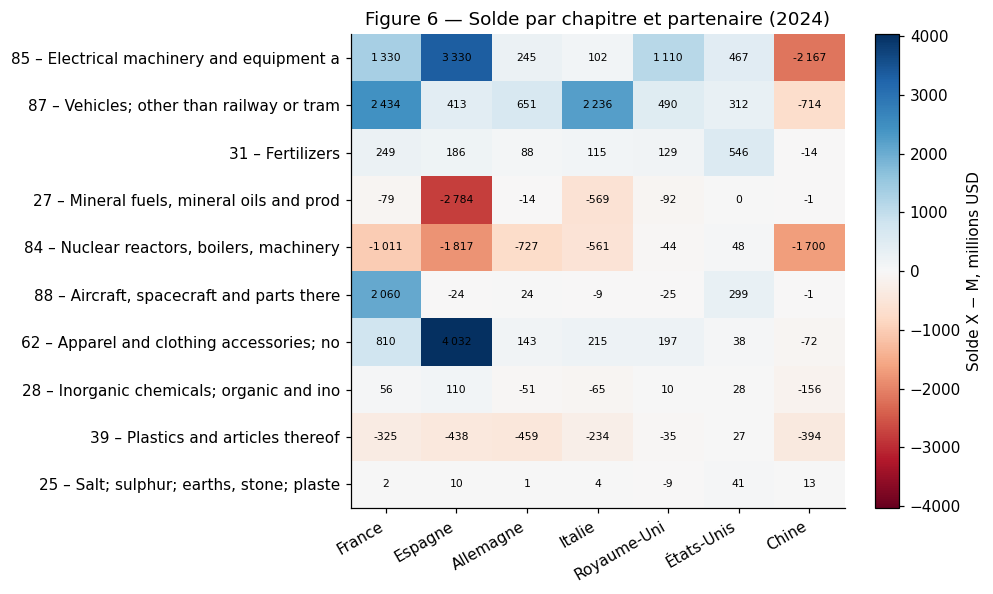

Lecture : un zéro peut signifier l'absence d'échange OU l'absence de déclaration (données miroir non interchangeables).


In [ ]:
# Figure 6 : carte de chaleur produit x partenaire (solde), année de référence
FICHIER_PHS = 'data/comtrade_partenaires_hs2.csv'
ph = pd.DataFrame()
try:
    if os.path.exists(FICHIER_PHS) and not FORCER_TELECHARGEMENT:
        ph = pd.read_csv(FICHIER_PHS, dtype={'cmdCode': str})
    else:
        ph = collecter([(ANNEE_REF, f, p, 'AG2') for f in FLUX for p in PARTENAIRES if p != 0])
        if not ph.empty:
            ph.to_csv(FICHIER_PHS, index=False)
    if ph.empty:
        raise ValueError('aucune donnée partenaire x HS2 reçue')
    ph['cmdCode'] = ph['cmdCode'].astype(str).str.strip().str.zfill(2)
    ph['valeur_musd'] = pd.to_numeric(ph['primaryValue'], errors='coerce') / 1e6
    ph = ph[ph.cmdCode.str.fullmatch(r'\d{2}')].drop_duplicates(['flowCode', 'partnerCode', 'cmdCode'])
    chap10 = (w['X'] + w['M']).sort_values(ascending=False).head(10).index
    m = ph[ph.cmdCode.isin(chap10)].pivot_table(index='cmdCode', columns=['flowCode', 'partnerCode'],
                                                values='valeur_musd', aggfunc='sum').fillna(0)
    parts = [p for p in PARTENAIRES if p != 0]
    solde_mat = pd.DataFrame({PARTENAIRES[p]: m['X'].get(p, 0) - m['M'].get(p, 0) for p in parts}).reindex(chap10)
    vmax = float(np.nanmax(np.abs(solde_mat.values))) or 1.0
    fig, ax = plt.subplots(figsize=(9, 5.5))
    im = ax.imshow(solde_mat.values, cmap='RdBu', vmin=-vmax, vmax=vmax, aspect='auto')
    ax.set_xticks(range(len(solde_mat.columns))); ax.set_xticklabels(solde_mat.columns, rotation=30, ha='right')
    ax.set_yticks(range(len(solde_mat.index))); ax.set_yticklabels([lib(c) for c in solde_mat.index])
    for i in range(solde_mat.shape[0]):
        for j in range(solde_mat.shape[1]):
            ax.text(j, i, fmt(solde_mat.values[i, j]), ha='center', va='center', fontsize=7)
    ax.grid(False)
    fig.colorbar(im, ax=ax, label='Solde X − M, millions USD')
    ax.set_title(f'Figure 6 — Solde par chapitre et partenaire ({ANNEE_REF})')
    sauver('fig6_carte_chaleur')
    print("Lecture : un zéro peut signifier l'absence d'échange OU l'absence de déclaration (données miroir non interchangeables).")
except Exception as e:
    print('Figure 6 non produite :', e)

## 7. Construction des variables

Projet descriptif : pas de cible future. Variables construites par chapitre HS2 (toutes années complètes) pour l'analyse exploratoire :

- `taille` = log10(1 + X moyen + M moyen) ;
- `specialisation` = (X − M)/(X + M), borné entre −1 (import pur) et +1 (export pur) ;
- `croissance_X` = log(1 + X dernière année) − log(1 + X première année).

Seuil de matérialité `SEUIL_MUSD` (X + M moyens) pour exclure les chapitres quasi nuls ; les valeurs absentes sont mises à 0 (hypothèse documentée : absence d'échange déclaré).

In [ ]:
panel = hs2.pivot_table(index='cmdCode', columns=['flowCode', 'refYear'], values='valeur_musd',
                        aggfunc='sum').fillna(0)
annees_l = sorted(annees_ok)

def construire_features(seuil):
    X_ = panel['X'].reindex(columns=annees_l, fill_value=0)
    M_ = panel['M'].reindex(columns=annees_l, fill_value=0)
    xm, mm = X_.mean(axis=1), M_.mean(axis=1)
    F = pd.DataFrame(index=panel.index)
    F['taille'] = np.log10(1 + xm + mm)
    den = (xm + mm).replace(0, np.nan)
    F['specialisation'] = (xm - mm) / den
    F['croissance_X'] = np.log1p(X_[annees_l[-1]]) - np.log1p(X_[annees_l[0]])
    F = F[(xm + mm) >= seuil].dropna()
    return F

SEUIL_MUSD = 1.0
F = construire_features(SEUIL_MUSD)
print(f'{len(F)} chapitres retenus sur {len(panel)} (seuil {SEUIL_MUSD} M USD).')
display(F.describe().round(2))

96 chapitres retenus sur 97 (seuil 1.0 M USD).


,taille,specialisation,croissance_X
count,96.00,96.00,96.00
mean,2.41,-0.43,0.63
std,0.87,0.56,0.57
min,0.34,-1.00,-0.83
25%,1.99,-0.86,0.31
50%,2.54,-0.65,0.61
75%,3.02,-0.13,0.90
max,4.15,0.90,2.11


## 8. Découpage et validation

Ce projet est descriptif : il n'y a pas de découpage train/test pour le tableau de bord. Deux garde-fous sont appliqués :

1. la **cohérence des totaux** (somme des chapitres vs total officiel) ;
2. un **mini-backtest chronologique** de la tendance (ajuster sur les années < t, prédire t), sans jamais utiliser l'année prédite. Avec ≤ 6 années, il ne sert qu'à illustrer la méthode, pas à conclure.

## 9. Modèle de référence

Référence : indicateurs de base (X, M, solde, couverture) et **persistance** (la valeur de l'année t est prédite par celle de t − 1).

In [ ]:
def backtest(serie, debut=3):
    res = []
    ys = serie.index.values.astype(float); vals = serie.values
    for i in range(debut, len(serie)):
        a, b = np.polyfit(ys[:i], vals[:i], 1)
        res.append((int(ys[i]), vals[i], vals[i - 1], a * ys[i] + b))
    return pd.DataFrame(res, columns=['annee', 'reel', 'persistance', 'tendance'])

comparaison = pd.DataFrame(columns=['modele', 'jeu_evalue', 'metrique', 'valeur'])
lignes = []
if len(tot) >= 4:
    for nom in ['X', 'M', 'solde']:
        bt = backtest(tot[nom])
        lignes.append(['Persistance', f'{nom}, années {bt.annee.min()}–{bt.annee.max()}', 'MAE (M USD)',
                       float((bt.reel - bt.persistance).abs().mean())])
        lignes.append(['Tendance linéaire', f'{nom}, années {bt.annee.min()}–{bt.annee.max()}', 'MAE (M USD)',
                       float((bt.reel - bt.tendance).abs().mean())])
else:
    print("Moins de 4 années complètes : backtest non réalisé (plan B : analyse descriptive seule).")
base = pd.DataFrame(lignes, columns=comparaison.columns)
display(base.round(1))

,modele,jeu_evalue,metrique,valeur
0,Persistance,"X, années 2022–2024",MAE (M USD),14661.2
1,Tendance linéaire,"X, années 2022–2024",MAE (M USD),13301.9
2,Persistance,"M, années 2022–2024",MAE (M USD),14380.4
3,Tendance linéaire,"M, années 2022–2024",MAE (M USD),12521.2
4,Persistance,"solde, années 2022–2024",MAE (M USD),7103.8
5,Tendance linéaire,"solde, années 2022–2024",MAE (M USD),8891.2


## 10. Deux modèles alternatifs

**Méthode A — décomposition de tendance** : pente linéaire, R², taux de croissance annuel moyen (TCAM). **Méthode B — clustering exploratoire des chapitres HS2** (`Pipeline` : standardisation + KMeans), comparé à une classification hiérarchique de Ward.

,série,pente (M USD/an),R²,TCAM (%)
0,X,8708.88,0.71,22.19
1,M,9336.52,0.84,13.92
2,solde,-627.64,0.04,NaN


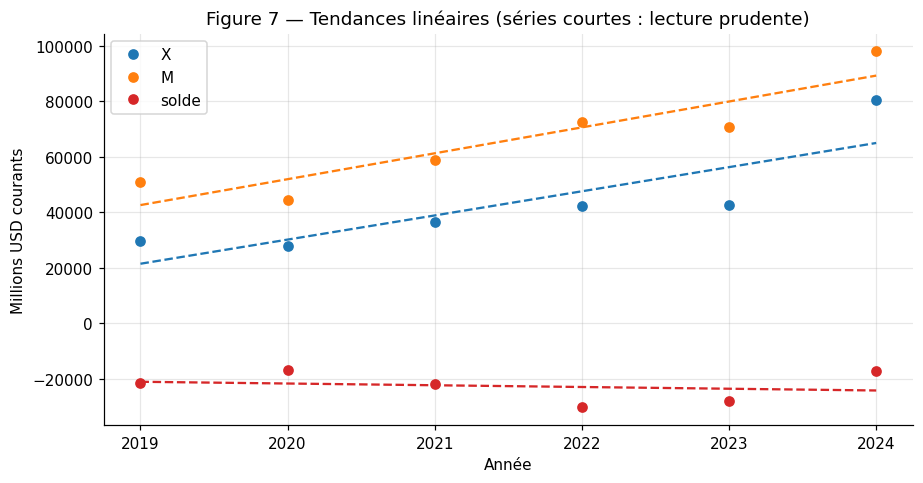

In [ ]:
# Méthode A : tendance
rows = []
for nom in ['X', 'M', 'solde']:
    y = tot[nom].values; x = tot.index.values.astype(float)
    if len(x) >= 3:
        a, b = np.polyfit(x, y, 1)
        res = y - (a * x + b)
        r2 = 1 - (res ** 2).sum() / ((y - y.mean()) ** 2).sum() if ((y - y.mean()) ** 2).sum() > 0 else np.nan
    else:
        a = r2 = np.nan
    tcam = ((y[-1] / y[0]) ** (1 / (len(y) - 1)) - 1) * 100 if (nom != 'solde' and len(y) > 1 and y[0] > 0) else np.nan
    rows.append([nom, a, r2, tcam])
tendance = pd.DataFrame(rows, columns=['série', 'pente (M USD/an)', 'R²', 'TCAM (%)'])
display(tendance.round(2))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for nom, coul in [('X', 'tab:blue'), ('M', 'tab:orange'), ('solde', 'tab:red')]:
    x = tot.index.values.astype(float); y = tot[nom].values
    ax.plot(x, y, 'o', color=coul, label=nom)
    if len(x) >= 3:
        a, b = np.polyfit(x, y, 1); ax.plot(x, a * x + b, '--', color=coul)
ax.set_title('Figure 7 — Tendances linéaires (séries courtes : lecture prudente)')
ax.set_xlabel('Année'); ax.set_ylabel('Millions USD courants'); ax.legend()
sauver('fig7_tendances')

## 11. Hyperparamètres

Espace restreint : nombre de groupes k ∈ {2, 3, 4, 5}. Critères non supervisés : silhouette (plus haut = mieux) et stabilité (indice de Rand ajusté moyen entre l'ajustement complet et 20 sous-échantillons à 80 %).

In [ ]:
def pipe_km(k, graine=GRAINE_ALEATOIRE):
    return Pipeline([('echelle', StandardScaler()),
                     ('km', KMeans(n_clusters=k, n_init=10, random_state=graine))])

def stabilite(F, k, n=20):
    ref = pipe_km(k).fit(F).predict(F)
    rng = np.random.default_rng(GRAINE_ALEATOIRE); aris = []
    for i in range(n):
        idx = rng.choice(len(F), size=int(0.8 * len(F)), replace=False)
        lab = pipe_km(k, graine=i).fit(F.iloc[idx]).predict(F)
        aris.append(adjusted_rand_score(ref, lab))
    return float(np.mean(aris))

grille = []
Xs = StandardScaler().fit_transform(F)
for k in [2, 3, 4, 5]:
    if len(F) <= k + 1:
        continue
    lab_km = pipe_km(k).fit(F).predict(F)
    lab_ag = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Xs)
    grille.append({'k': k,
                   'silhouette KMeans': silhouette_score(Xs, lab_km),
                   'silhouette Ward': silhouette_score(Xs, lab_ag),
                   'stabilité (ARI moyen)': stabilite(F, k),
                   'accord KMeans/Ward (ARI)': adjusted_rand_score(lab_km, lab_ag)})
grille = pd.DataFrame(grille)
display(grille.round(3))
K_OPT = int(grille.loc[grille['silhouette KMeans'].idxmax(), 'k'])
print('k retenu (silhouette maximale) :', K_OPT)

,k,silhouette KMeans,silhouette Ward,stabilité (ARI moyen),accord KMeans/Ward (ARI)
0,2,0.286,0.249,0.652,0.757
1,3,0.327,0.316,0.877,0.806
2,4,0.340,0.262,0.830,0.515
3,5,0.336,0.283,0.821,0.512


k retenu (silhouette maximale) : 4


## 12. Évaluation

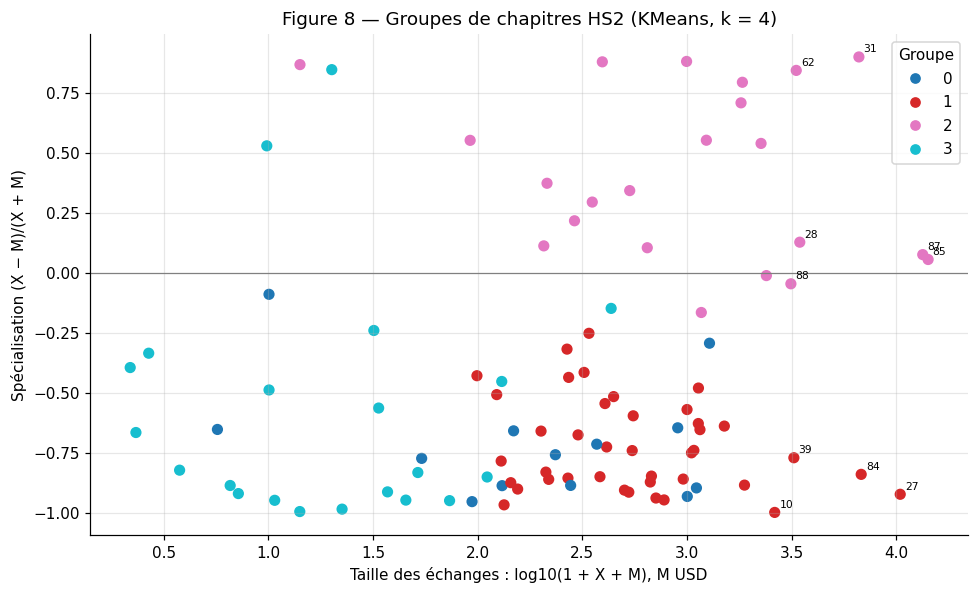

,groupe,nb,taille,specialisation,croissance_X,chapitres
0,0,13,2.37,-0.76,1.47,"17, 18, 40, 47, 49, 53, 55, 58"
1,1,40,2.71,-0.76,0.60,"01, 04, 06, 09, 10, 15, 19, 21"
2,2,22,3.08,0.36,0.73,"03, 05, 07, 08, 13, 16, 20, 25"
3,3,21,1.30,-0.82,-0.07,"02, 11, 12, 14, 36, 37, 41, 43"


,modele,jeu_evalue,metrique,valeur
0,Persistance,"X, années 2022–2024",MAE (M USD),14661.219
1,Tendance linéaire,"X, années 2022–2024",MAE (M USD),13301.898
2,Persistance,"M, années 2022–2024",MAE (M USD),14380.401
3,Tendance linéaire,"M, années 2022–2024",MAE (M USD),12521.218
4,Persistance,"solde, années 2022–2024",MAE (M USD),7103.837
5,Tendance linéaire,"solde, années 2022–2024",MAE (M USD),8891.204
6,Cohérence des totaux,toutes années,Somme chapitres / total X (% moyen),100.000
7,Cohérence des totaux,toutes années,Somme chapitres / total M (% moyen),100.000
8,KMeans,k=4,Silhouette,0.340
9,KMeans,k=4,Stabilité (ARI moyen),0.830


In [ ]:
lab = pipe_km(K_OPT).fit(F).predict(F)
F_cl = F.copy(); F_cl['groupe'] = lab
F_cl['libelle'] = [lib(c) if c in w.index else c for c in F_cl.index]

fig, ax = plt.subplots(figsize=(9, 5.5))
sc = ax.scatter(F_cl['taille'], F_cl['specialisation'], c=F_cl['groupe'], cmap='tab10', s=40)
for c_, row in F_cl.sort_values('taille', ascending=False).head(10).iterrows():
    ax.annotate(c_, (row['taille'], row['specialisation']), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax.axhline(0, color='grey', lw=.8)
ax.set_title(f'Figure 8 — Groupes de chapitres HS2 (KMeans, k = {K_OPT})')
ax.set_xlabel('Taille des échanges : log10(1 + X + M), M USD'); ax.set_ylabel('Spécialisation (X − M)/(X + M)')
ax.legend(*sc.legend_elements(), title='Groupe', loc='best')
sauver('fig8_groupes_hs2')

desc_cl = (F_cl.groupby('groupe')
           .agg(nb=('taille', 'size'), taille=('taille', 'median'),
                specialisation=('specialisation', 'median'), croissance_X=('croissance_X', 'median'),
                chapitres=('libelle', lambda s: ', '.join(x.split(' – ')[0] for x in s.head(8))))
           .reset_index())
display(desc_cl.round(2))

ligne_k = grille[grille.k == K_OPT].iloc[0]
eval_rows = [
    ['Cohérence des totaux', 'toutes années', 'Somme chapitres / total X (% moyen)', float(coh.iloc[:, 1].mean())],
    ['Cohérence des totaux', 'toutes années', 'Somme chapitres / total M (% moyen)', float(coh.iloc[:, 2].mean())],
    ['KMeans', f'k={K_OPT}', 'Silhouette', float(ligne_k['silhouette KMeans'])],
    ['KMeans', f'k={K_OPT}', 'Stabilité (ARI moyen)', float(ligne_k['stabilité (ARI moyen)'])],
    ['Ward', f'k={K_OPT}', 'Silhouette', float(ligne_k['silhouette Ward'])],
]
comparaison = pd.concat([base, pd.DataFrame(eval_rows, columns=comparaison.columns)], ignore_index=True)
display(comparaison.round(3))

## 13. Sensibilité et interprétation

- Stabilité du top 10 des exportations selon l'année de référence.
- Sensibilité de la silhouette au seuil de matérialité.

In [ ]:
top_ref = set(panel['X'][ANNEE_REF].sort_values(ascending=False).head(10).index)
sens_annee = []
for a in annees_l:
    t = set(panel['X'][a].sort_values(ascending=False).head(10).index)
    rho = panel['X'][a].rank().corr(panel['X'][ANNEE_REF].rank(), method='spearman')
    sens_annee.append([a, len(t & top_ref), float(rho)])
sens_annee = pd.DataFrame(sens_annee, columns=['année', 'recouvrement top 10 avec année réf.', 'Spearman (rangs X)'])
display(sens_annee.round(3))

sens_seuil = []
for sd in [0, 1, 10, 50]:
    Fi = construire_features(sd)
    if len(Fi) > K_OPT + 1:
        lab_i = pipe_km(K_OPT).fit(Fi).predict(Fi)
        sens_seuil.append([sd, len(Fi), float(silhouette_score(StandardScaler().fit_transform(Fi), lab_i))])
sens_seuil = pd.DataFrame(sens_seuil, columns=['seuil (M USD)', 'nb chapitres', 'silhouette'])
display(sens_seuil.round(3))
print('Limites : séries annuelles courtes, valeurs courantes (effet prix/change non isolé), '
      "aucune causalité établie, preview Comtrade limitée à 500 lignes par requête.")

,année,recouvrement top 10 avec année réf.,Spearman (rangs X)
0,2019,9,0.974
1,2020,9,0.975
2,2021,9,0.970
3,2022,9,0.981
4,2023,9,0.991
5,2024,10,1.000


,seuil (M USD),nb chapitres,silhouette
0,0,97,0.335
1,1,96,0.340
2,10,85,0.297
3,50,77,0.322


Limites : séries annuelles courtes, valeurs courantes (effet prix/change non isolé), aucune causalité établie, preview Comtrade limitée à 500 lignes par requête.


## 14. Conclusion commerciale

La cellule suivante produit un résumé factuel. Les recommandations sous conditions sont rédigées par le binôme dans le rapport, à partir de ces chiffres.

In [ ]:
p1 = w['X'].idxmax(); d1 = w['solde'].idxmin()
print(f"Sur {ANNEE_REF}, le Maroc a exporté {fmt(r.X)} M USD et importé {fmt(r.M)} M USD de marchandises "
      f"(solde {fmt(r.solde)} M USD ; couverture {r.couverture_pct:.1f} %).")
print(f"Premier chapitre exporté : {lib(p1)} ({w.loc[p1,'part_X_pct']:.1f} % des X). "
      f"Plus fort déficit sectoriel : {lib(d1)} ({fmt(w.loc[d1,'solde'])} M USD).")
print(f"Parmi les partenaires retenus, premier client : {pm} ({pa.loc[pm,'part_X_pct']:.1f} % des X totales).")
print("À faire par le binôme : confronter ces chiffres à une source nationale (Office des changes / bkam.ma) "
      "et formuler des recommandations conditionnelles.")

Sur 2024, le Maroc a exporté 80 569 M USD et importé 97 953 M USD de marchandises (solde -17 385 M USD ; couverture 82.3 %).
Premier chapitre exporté : 87 – Vehicles; other than railway or tram (20.3 % des X). Plus fort déficit sectoriel : 27 – Mineral fuels, mineral oils and prod (-10 973 M USD).
Parmi les partenaires retenus, premier client : Espagne (22.6 % des X totales).
À faire par le binôme : confronter ces chiffres à une source nationale (Office des changes / bkam.ma) et formuler des recommandations conditionnelles.


## 15. Reproductibilité

Cette dernière cellule exporte tous les tableaux (`tables/*.tex`) et les valeurs-clés (`tables/valeurs.tex`) lues par le rapport LaTeX, afin qu'aucun chiffre ne soit recopié à la main. Les figures sont déjà dans `figures/`.

In [ ]:
TEX = True

def echapper(s):
    s = str(s)
    for a, b in (('\\', '\\textbackslash{}'), ('&', '\\&'), ('%', '\\%'), ('_', '\\_'), ('#', '\\#'), ('$', '\\$'), ('−', '$-$')):
        s = s.replace(a, b)
    return s

def tex_table(d, chemin, decimales=1):
    cols = list(d.columns)
    align = ''.join('r' if pd.api.types.is_numeric_dtype(d[c]) else 'l' for c in cols)
    L = ['\\begin{tabular}{' + align + '}', '\\toprule',
         ' & '.join(echapper(c) for c in cols) + ' \\\\', '\\midrule']
    for _, row in d.iterrows():
        cells = []
        for c in cols:
            v = row[c]
            if pd.api.types.is_numeric_dtype(d[c]):
                if pd.isna(v): cells.append('--')
                elif pd.api.types.is_integer_dtype(d[c]) or c in ('k', 'année', 'nb', 'groupe'): cells.append(str(int(v)))
                else: cells.append(fmt(float(v), decimales))
            else:
                cells.append(echapper(v))
        L.append(' & '.join(cells) + ' \\\\')
    L += ['\\bottomrule', '\\end{tabular}']
    with open(chemin, 'w', encoding='utf-8') as fh:
        fh.write('\n'.join(L) + '\n')

kpi = tot.reset_index().rename(columns={'refYear': 'année', 'X': 'X (M USD)', 'M': 'M (M USD)',
                                        'solde': 'Solde (M USD)', 'couverture_pct': 'Couverture (%)',
                                        'var_X_pct': 'Var. X (%)', 'var_M_pct': 'Var. M (%)'})
kpi['année'] = kpi['année'].astype(int)
tex_table(kpi, 'tables/kpi.tex', 1)

tp = w.sort_values('X', ascending=False).head(10).reset_index()
tp = pd.DataFrame({'HS2': tp['cmdCode'], 'Libellé': tp['libelle'].str[:40], 'X (M USD)': tp['X'],
                   'M (M USD)': tp['M'], 'Solde (M USD)': tp['solde'], 'Part X (%)': tp['part_X_pct']})
tex_table(tp, 'tables/top_chapitres.tex', 1)

td = w.sort_values('solde').head(5).reset_index()
td = pd.DataFrame({'HS2': td['cmdCode'], 'Libellé': td['libelle'].str[:40], 'X (M USD)': td['X'],
                   'M (M USD)': td['M'], 'Solde (M USD)': td['solde']})
tex_table(td, 'tables/top_deficits.tex', 1)

tpa = pa.reset_index().rename(columns={'index': 'Partenaire', 'X': 'X (M USD)', 'M': 'M (M USD)',
                                       'solde': 'Solde (M USD)', 'part_X_pct': 'Part X (%)', 'part_M_pct': 'Part M (%)'})
tex_table(tpa, 'tables/partenaires.tex', 1)
tex_table(coh, 'tables/coherence.tex', 2)
tex_table(dictionnaire, 'tables/dictionnaire.tex', 1)
tex_table(tendance, 'tables/tendance.tex', 2)
tex_table(grille.rename(columns={'k': 'k'}), 'tables/hyperparametres.tex', 3)
tex_table(desc_cl, 'tables/groupes.tex', 2)
tex_table(comparaison, 'tables/comparaison.tex', 3)
tex_table(sens_annee, 'tables/sensibilite_annee.tex', 2)
tex_table(sens_seuil, 'tables/sensibilite_seuil.tex', 3)

macros = {
    'anneeref': str(ANNEE_REF),
    'anneesdisp': f"{min(annees_ok)}--{max(annees_ok)}",
    'nbannees': str(len(annees_ok)),
    'expref': fmt(r.X), 'impref': fmt(r.M), 'soldref': fmt(r.solde),
    'couvref': fmt(r.couverture_pct, 1),
    'prodtop': echapper(lib(p1)), 'prodtoppart': fmt(w.loc[p1, 'part_X_pct'], 1),
    'proddef': echapper(lib(d1)), 'proddefsolde': fmt(w.loc[d1, 'solde']),
    'parttop': echapper(pm), 'parttoppart': fmt(pa.loc[pm, 'part_X_pct'], 1),
    'nbchap': str(len(F)), 'kopt': str(K_OPT),
    'silopt': fmt(float(ligne_k['silhouette KMeans']), 2),
    'ariopt': fmt(float(ligne_k['stabilité (ARI moyen)']), 2),
}
with open('tables/valeurs.tex', 'w', encoding='utf-8') as fh:
    for k_, v_ in macros.items():
        fh.write('\\renewcommand{\\' + k_ + '}{' + v_ + '}\n')

with open('data/versions.txt', 'w') as fh:
    fh.write(f"python {platform.python_version()}\nnumpy {np.__version__}\npandas {pd.__version__}\n"
             f"scikit-learn {sklearn.__version__}\nmatplotlib {matplotlib.__version__}\n"
             f"requests {requests.__version__}\nseed {GRAINE_ALEATOIRE}\n")
print(open('data/versions.txt').read())
print('Tables LaTeX :', sorted(os.listdir('tables')))
print('Figures :', sorted(os.listdir('figures')))

python 3.13.18
numpy 2.4.6
pandas 2.2.3
scikit-learn 1.6.1
matplotlib 3.10.0
requests 2.32.4
seed 42

Tables LaTeX : ['coherence.tex', 'comparaison.tex', 'dictionnaire.tex', 'groupes.tex', 'hyperparametres.tex', 'kpi.tex', 'partenaires.tex', 'sensibilite_annee.tex', 'sensibilite_seuil.tex', 'tendance.tex', 'top_chapitres.tex', 'top_deficits.tex', 'valeurs.tex']
Figures : ['fig1_x_m_solde.png', 'fig2_couverture.png', 'fig3_top_export.png', 'fig4_soldes_produits.png', 'fig5_partenaires.png', 'fig6_carte_chaleur.png', 'fig7_tendances.png', 'fig8_groupes_hs2.png']
